## **Notebook B – Marché**

Ce document présente les analyses effectuées en vue d'établir le marché existant pour les locations courte durée à Amsterdam en vue d'établir une recommandation fiable (voir Notebook C et Note de décision).

### • Partie B1 – Création de variables

In [21]:
# Importation des données
import pandas as pd
import numpy as np

listclean=pd.read_csv('listings_propre.csv')
revclean=pd.read_csv('reviews_propre.csv')

print(listclean.shape)
print(revclean.shape)

(10612, 29)
(552748, 5)


Nouvelles variables:

In [22]:
# Annonce active : dernière review publiée cette année (2026)
listclean['active'] = np.where(listclean['last_review'].str[:4] == '2026', 'yes', 'no')

# Hôte multi-annonce (2 annonces ou plus)
listclean['multi_host'] = np.where(listclean['host_id'].duplicated(), 'yes', 'no')

# Logement entier (oui/non)
listclean['entire_home'] = np.where(listclean['room_type']=='entire home/apt', 'yes', 'no')

# Prix par personne (ratio 'price'/'accomodates')
listclean['price_pp'] = listclean['price']/listclean['accommodates']

# Ancienneté de l'hôte (en mois : on convertit les années en mois)
listclean['host_tenure'] = (listclean['hosts_time_as_host_years']*12)+listclean['hosts_time_as_host_months']

# Nombre d'équipements
listclean['Nb_amenities'] = listclean['amenities'].str.split(',').str.len()

# Durée minimale : variable non pertinente (pas de seuil réglementaire minimal à Amsterdam)
# Statut de la licence : déjà renseigné dans la variable 'statut_licence' créée dans le notebook A

print(listclean.head())

   number_of_reviews_ltm last_review  availability_365  \
0                      0  2024-05-18                17   
1                     14  2026-08-24               299   
2                      4  2026-08-09                 6   
3                      0  2025-08-10                 0   
4                      0  2022-09-11                 0   

   calculated_host_listings_count        room_type   price  accommodates  \
0                               1  entire home/apt  358.00           2.0   
1                               3     private room  485.00           4.0   
2                               1  entire home/apt  226.67           2.0   
3                               1  entire home/apt     NaN           4.0   
4                               1  entire home/apt     NaN           2.0   

   hosts_time_as_host_months  hosts_time_as_host_years  \
0                          4                         2   
1                          8                         6   
2                   

### • Partie B2 – Combinaison des données

Agréger 'reviews' par annonce : nombre d’avis, date du dernier avis, avis des 12 derniers mois :

In [23]:
# 1. Définir la date de référence pour les 12 derniers mois : date de scrapping ('last_scraped' dans 'listings')
revclean['date'] = pd.to_datetime(revclean['date'])
date_ref = revclean['date'].max()
# Date de ref correspond à la date de scraping de 'listclean':
# listclean['last_scraped'][1]
time_difference = date_ref - pd.DateOffset(months=12)

rev_recent = revclean[revclean['date'] >= time_difference] # Sélectionner les 12 derniers mois

# 2. Grouper
group = rev_recent.groupby('listing_id').agg(
    nombre_avis=('id', 'count'), # Nombre d'avis uniques par annonce
    dernier_avis=('date', 'max'), # Date du dernier avis
    avis_12_derniers_mois=('comments', lambda x: ' '.join(x.dropna().astype(str))) # Avis sur les 12 derniers mois
)

print(group.head())

            nombre_avis dernier_avis  \
listing_id                             
28871                82   2026-08-29   
29051                77   2026-08-29   
49552                56   2026-09-07   
50523                86   2026-09-02   
62015                 1   2025-10-25   

                                        avis_12_derniers_mois  
listing_id                                                     
28871       Nuestra estadía con Edwin fue placentera, el A...  
29051       Very good Location for tourists close to the o...  
49552       This place was in a great location.  <br/>We w...  
50523       This was a wonderful place to stay for my visi...  
62015                      10/10 stay, would highly recommend  


Joindre cette nouvelle table à 'listings' :

In [24]:
fulldata = listclean.merge(
    group,
    left_on='id',
    right_index=True,
    indicator=True,
    how='left' # Garder toutes les annonces de 'listings', même ceux qui n'ont pas d'avis dans 'reviews'
)

print(fulldata.head())

   number_of_reviews_ltm last_review  availability_365  \
0                      0  2024-05-18                17   
1                     14  2026-08-24               299   
2                      4  2026-08-09                 6   
3                      0  2025-08-10                 0   
4                      0  2022-09-11                 0   

   calculated_host_listings_count        room_type   price  accommodates  \
0                               1  entire home/apt  358.00           2.0   
1                               3     private room  485.00           4.0   
2                               1  entire home/apt  226.67           2.0   
3                               1  entire home/apt     NaN           4.0   
4                               1  entire home/apt     NaN           2.0   

   hosts_time_as_host_months  hosts_time_as_host_years  \
0                          4                         2   
1                          8                         6   
2                   

Nous avons choisi de garder l'ensemble des données : plutôt qu'un *inner join*, un *left join* permet de conserver l'ensemble des 10612 lignes de 'listclean'. Des données manquantes sont introduites dans les colonnes de 'revclean' fusionnées dans le jeu de données complet pour les biens listés qui n'ont pas de review documentée sur les 12 derniers mois.

La colonne '_merge' (produite par 'indicator = TRUE') permet de vérifier quelles observations présentent des reviews ('both') ou non ('left_only').

Sources permettant de rapporter l'offre totale à la population:

- La population totale de la ville d'Amsterdam est de 950787 habitants (estimation septembre 2026), disponible sur **le site de l'Institut Statistique National des Pays-Bas** (*Centraal Bureau voor de Statistiek*) :  
https://opendata.cbs.nl/#/CBS/nl/dataset/37230ned/table?searchKeywords=inkomen%20amsterdam
- Cette population est répartie de manière inégale, avec une concentration plus importante dans l'hypercentre qui décroit progressivement dans les quartiers qui en sont les plus éloignés (nous avons utilisé les 25 quartiers administratifs tels que listés sur le site de la municipalité).  
- Les quartiers les plus peuplés sont aussi globalement ceux qui présentent le plus grand nombre de logements et la plus grande proportion de logements dont les propriétaires sont des particuliers, comme visible dans le tableau ci-dessous.

In [27]:
from IPython.display import display

data = [
    (2026, "Oud-West, De Baarsjes", 71590, 40810, 15100),
    (2026, "De Pijp, Rivierenbuurt", 63980, 38995, 15950),
    (2026, "Oud-Zuid", 53306, 29531, 13040),
    (2026, "Slotervaart", 48770, 24549, 9390),
    (2026, "Centrum-Oost", 46498, 28167, 10045),
    (2026, "Geuzenveld, Slotermeer", 45913, 19822, 2345),
    (2026, "Centrum-West", 43905, 29688, 12820),
    (2026, "Indische Buurt, Oostelijk Havengebied", 42258, 22341, 5280),
    (2026, "Osdorp", 42071, 18911, 3710),
    (2026, "Westerpark", 41401, 24608, 6400),
    (2026, "Noord-West", 40204, 17173, 1155),
    (2026, "Watergraafsmeer", 40047, 21151, 7305),
    (2026, "Oud-Noord", 37604, 20788, 5755),
    (2026, "Bos en Lommer", 35563, 19061, 5360),
    (2026, "Oud-Oost", 35293, 19716, 3935),
    (2026, "Noord-Oost", 34705, 16302, 2855),
    (2026, "Gaasperdam", 32834, 15133, 1980),
    (2026, "IJburg, Zeeburgereiland", 32536, 15096, 4725),
    (2026, "Bijlmer-Oost", 30394, 13341, 2070),
    (2026, "Buitenveldert, Zuidas", 29109, 16388, 6905),
    (2026, "De Aker, Sloten, Nieuw-Sloten", 28903, 11637, 2960),
    (2026, "Weesp, Driemond", 27759, 11596, 1180),
    (2026, "Bijlmer-Centrum", 26710, 14069, 4815),
    (2026, "Bijlmer-West", 5447, 3466, 3010),
    (2026, "Sloterdijk Nieuw-West", 2954, 2092, 1425),
]

columns = ["Year", "Quartier", "Population", "Nb_logements", "Dont_particuliers"]
df = pd.DataFrame(data, columns=columns)

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(df)

,Year,Quartier,Population,Nb_logements,Dont_particuliers
0,2026,"Oud-West, De Baarsjes",71590,40810,15100
1,2026,"De Pijp, Rivierenbuurt",63980,38995,15950
2,2026,Oud-Zuid,53306,29531,13040
3,2026,Slotervaart,48770,24549,9390
4,2026,Centrum-Oost,46498,28167,10045
5,2026,"Geuzenveld, Slotermeer",45913,19822,2345
6,2026,Centrum-West,43905,29688,12820
7,2026,"Indische Buurt, Oostelijk Havengebied",42258,22341,5280
8,2026,Osdorp,42071,18911,3710
9,2026,Westerpark,41401,24608,6400


Par ailleurs, le nombre de logements disponibles sur Airbnb tel que mesuré par la municipalité entre 2017 et 2022 (pas de données disponibles en dehors de cet intervalle de temps) a drastiquement diminué, en particulier entre 2021 et 2022 (disparition de plus de la moitié des annonces en un an), suite aux durcissements progressifs de la législation (voir partie A1) :

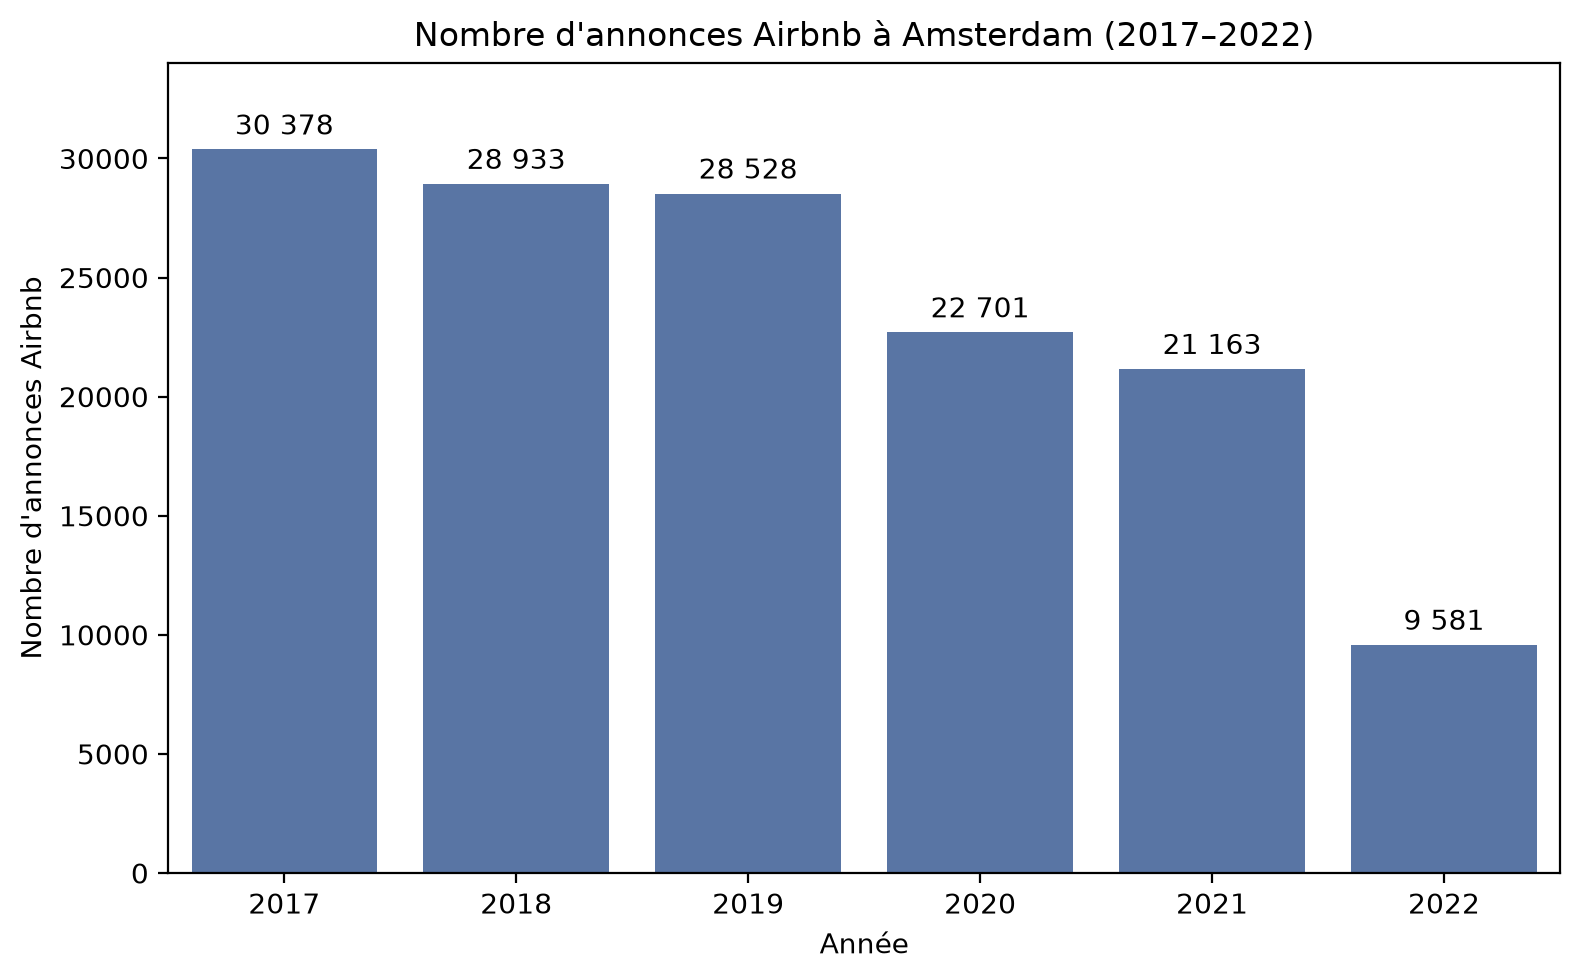

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Charger l'onglet 'data', filtrer sur 2017–2022 et trier par année
df = pd.read_excel("BHVESTAIRBNB-2019-gemeenten.xlsx", sheet_name="data")
df_plot = df[(df["Year"] >= 2017) & (df["Year"] <= 2022)].sort_values("Year")

# 2. Créer le barplot
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_plot, x="Year", y="Airbnb listings", color="#4C72B0", legend=False
)

# Ajouter les étiquettes de valeur au-dessus de chaque barre
for container in ax.containers:
    labels = [f"{int(bar.get_height()):,}".replace(",", " ") for bar in container]
    ax.bar_label(container, labels=labels, padding=3)

plt.ylim(0, df_plot["Airbnb listings"].max() * 1.12)
plt.title("Nombre d'annonces Airbnb à Amsterdam (2017–2022)")
plt.xlabel("Année")
plt.ylabel("Nombre d'annonces Airbnb")
plt.tight_layout()
plt.show()

Les données du tableau et du graphique ci-dessus proviennent toutes de **la section 'Recherche et statistique' (*Onderzoek en Statistiek*) du site de la ville d'Amsterdam**, consultable en anglais :  
https://onderzoek.amsterdam.nl/interactief/dashboard-kerncijfers?tab=indicator&thema=bevolking&indicator=BEVTOTAAL&indeling=ggwgebieden&jaar=2026&gebied=GA01&taal=en